# Lab 3: Naive Bayes

In [1]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import CategoricalNB

traffic = pd.read_csv("./traffic.txt")
X = traffic.loc[:, ["Weather", "Day"]]
y = traffic.loc[:, "HighTraffic"]

In [2]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder = encoder.fit(X)
X = encoder.transform(X)

In [3]:
clf = CategoricalNB(alpha=0)
clf.fit(X, y)

.../site-packages/sklearn/naive_bayes.py:1504: RuntimeWarning: divide by zero encountered in log
  np.log(smoothed_cat_count) - np.log(smoothed_class_count.reshape(-1, 1))


CategoricalNB(alpha=0)

In [4]:
new_data = pd.DataFrame({"Weather": ["Hot"], "Day": ["Vacation"]})
transformed_new_data = encoder.transform(new_data)
print(clf.predict(transformed_new_data))
print(clf.predict_proba(transformed_new_data))

['No']
[[0.66666667 0.33333333]]


In [5]:
clf = CategoricalNB(alpha=1)
clf.fit(X, y)

CategoricalNB(alpha=1)

In [6]:
new_data = pd.DataFrame({"Weather": ["Hot"], "Day": ["Weekend"]})
transformed_new_data = encoder.transform(new_data)
print(clf.predict(transformed_new_data))
print(clf.predict_proba(transformed_new_data))

['Yes']
[[0.25 0.75]]


In [7]:
from sklearn import datasets
from sklearn.naive_bayes import GaussianNB
import numpy as np

iris = datasets.load_iris()
data = iris.data[:, [0, 1]]
target = iris.target
target[100:125] = 1
target[125:150] = 0

In [8]:
xtrain = np.concatenate((data[0:40], data[50:90], data[100:140]))
ytrain = np.concatenate((target[0:40], target[50:90], target[100:140]))

In [9]:
xtest = np.concatenate((data[40:50], data[90:100], data[140:150]))
ytest = np.concatenate((target[40:50], target[90:100], target[140:150]))

In [10]:
clf = GaussianNB()
clf.fit(xtrain, ytrain)
pred = clf.predict(xtest)
predprob = clf.predict_proba(xtest)
print(pred)
print(predprob)

[0 1 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1]
[[0.94053785 0.05946215]
 [0.48353856 0.51646144]
 [0.95186874 0.04813126]
 [0.94053785 0.05946215]
 [0.98130867 0.01869133]
 [0.77209114 0.22790886]
 [0.98130867 0.01869133]
 [0.92092745 0.07907255]
 [0.95592566 0.04407434]
 [0.87098505 0.12901495]
 [0.18704625 0.81295375]
 [0.26129289 0.73870711]
 [0.12638719 0.87361281]
 [0.21927211 0.78072789]
 [0.20709549 0.79290451]
 [0.37370391 0.62629609]
 [0.29707676 0.70292324]
 [0.18377903 0.81622097]
 [0.27096248 0.72903752]
 [0.23358156 0.76641844]
 [0.23620861 0.76379139]
 [0.22050525 0.77949475]
 [0.16215739 0.83784261]
 [0.30108744 0.69891256]
 [0.40275594 0.59724406]
 [0.17705415 0.82294585]
 [0.05796599 0.94203401]
 [0.19639188 0.80360812]
 [0.60183462 0.39816538]
 [0.31067736 0.68932264]]


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

print("Accuracy: ", accuracy_score(ytest, pred))
print("Precision: ", precision_score(ytest, pred, pos_label=1))
print("Recall: ", recall_score(ytest, pred, pos_label=1))
print("F1 Score: ", f1_score(ytest, pred, pos_label=1))

Accuracy:  0.6666666666666666
Precision:  0.5
Recall:  1.0
F1 Score:  0.6666666666666666


In [12]:
fpr, tpr, thresholds = roc_curve(ytest, predprob[:, 1])
print("AUC: ", auc(fpr, tpr))

AUC:  0.77


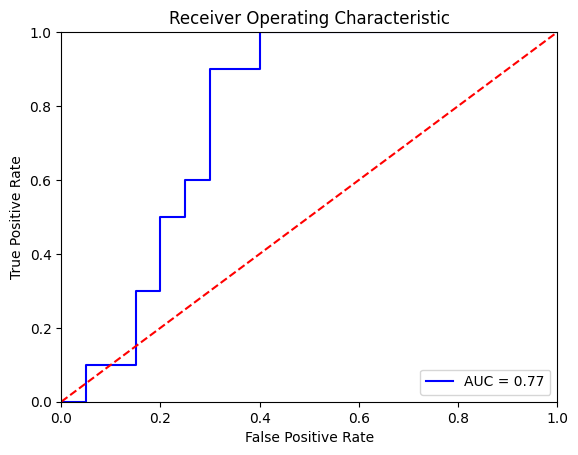

In [13]:
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % auc(fpr, tpr))
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()